# Quartz: elastic constants, sound and heat capacity

Alpha-quartz, the common form of SiO₂, is a crystal of SiO₄ tetrahedra that share
their corners. It is not cubic: along its c axis it is stiffer than across it, and it
needs six elastic constants instead of the three of a cubic crystal. Here a model of
quartz is relaxed at room temperature, stretched and sheared to measure its elastic
constants, and the constants are turned into speeds of sound and a Debye
temperature. The vibrations of the atoms themselves show what the Debye model leaves
out, and what that means for the heat capacity at room temperature.

The model is BKS (van Beest, Kramer and van Santen, 1990): charges on Si and O, and a
Buckingham term A exp(−r/ρ) − C/r⁶ for the Si–O and O–O pairs. Units are LAMMPS
`metal` units: Å, ps, eV, K and bar.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from fys2160_md import AlphaQuartz, Buckingham, MDSimulation

## The crystal and the force field

`AlphaQuartz` builds the measured room-temperature structure. The box holds 4 × 2 × 3
rectangular cells of 18 atoms: 432 atoms, with the hexagonal a axis along x and the c
axis along z. Seen along c (left), the tetrahedra leave open hexagonal channels.

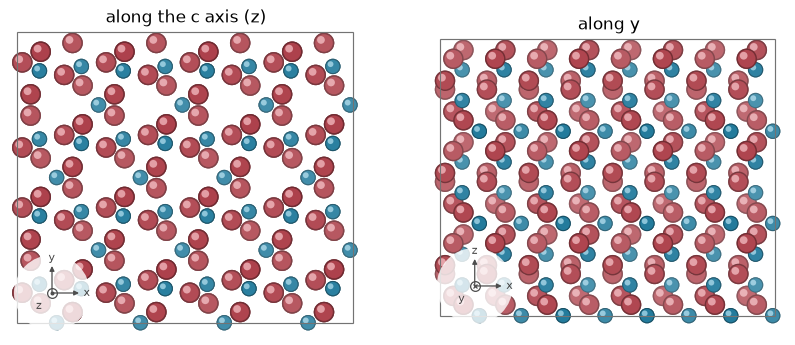

In [2]:
quartz = AlphaQuartz(cells=(4, 2, 3))
fig, (top, side) = plt.subplots(1, 2, figsize=(10, 4.5))
quartz.draw(ax=top, view="top", projection="orthographic")
quartz.draw(ax=side, view="front", projection="orthographic")
top.set_title("along the c axis (z)")
side.set_title("along y")
plt.show()

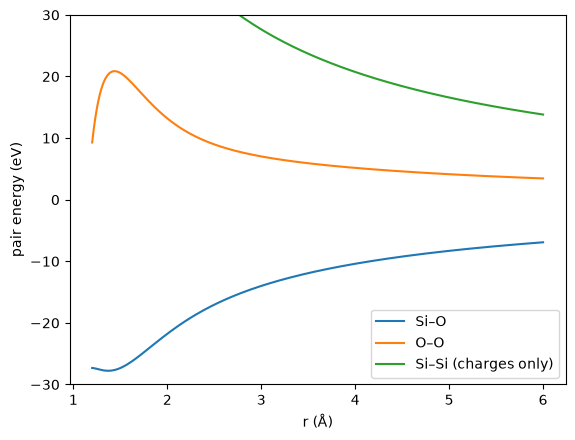

In [3]:
bks = {
    ("O", "O"): Buckingham(A=1388.7730, rho=0.362319, C=175.0),     # eV, Å, eV Å^6
    ("Si", "O"): Buckingham(A=18003.7572, rho=0.205205, C=133.5381),
}
charge = {"Si": 2.4, "O": -1.2}                                       # e

r = np.linspace(1.2, 6, 300)
coulomb = 14.399645                                                   # eV Å/e^2
plt.plot(r, bks[("Si", "O")].energy(r) + coulomb*charge["Si"]*charge["O"]/r, label="Si–O")
plt.plot(r, bks[("O", "O")].energy(r) + coulomb*charge["O"]**2/r, label="O–O")
plt.plot(r, coulomb*charge["Si"]**2/r, label="Si–Si (charges only)")
plt.ylim(-30, 30)
plt.xlabel("r (Å)")
plt.ylabel("pair energy (eV)")
plt.legend()
plt.show()

Si and O attract strongly and settle at about 1.6 Å, the length of the Si–O bond;
equal ions repel. (Very close, below about 1.1 Å, the −C/r⁶ term would win and pull
Si and O together without limit; at room temperature no atoms get near.)

## Relax at room temperature and zero pressure

The measured structure is not exactly the BKS structure, so first let the crystal
find its own size at 300 K and 0 bar. `barostat="anisotropic"` lets the three box
lengths change separately, each driven by its own component of the pressure tensor.
The pairs beyond the cutoff still attract through −C/r⁶; `tail=True` adds that
energy and pressure for a uniform density beyond the cutoff (with `lj_shift=False`).

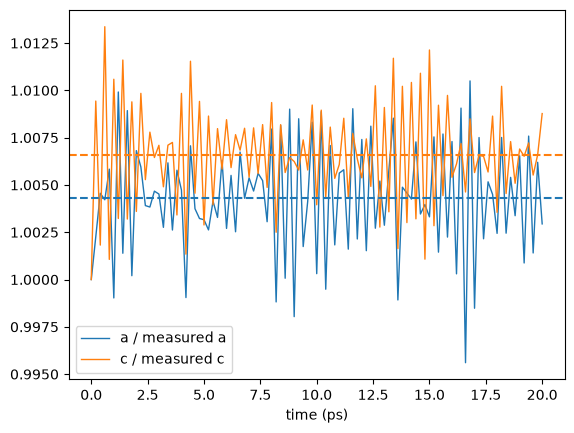

a = 4.9347 Å (measured 4.9134), c = 5.4407 Å (measured 5.4052)
density 2.609 g/cm^3 (measured 2.648)


In [4]:
relax = MDSimulation(
    units="metal",
    pair_potential=bks,
    charge=charge,
    coulomb="pppm",
    kspace_accuracy=1e-4,
    lj_shift=False,
    tail=True,
    ensemble="npt",
    barostat="anisotropic",
    temperature=300,          # K
    pressure=0.0,             # bar
    timestep=0.001,           # ps
    cutoff=8.0,               # Å
)
relaxed = relax.run(quartz, steps=20_000, thermo_every=100, trajectory_every=200, storage_name="quartz-relax")

a = relaxed.boxes[:, 0]/4               # Å, one value per saved frame (every 0.2 ps)
c = relaxed.boxes[:, 2]/3
plt.plot(relaxed.times, a/4.9134, lw=1, label="a / measured a")
plt.plot(relaxed.times, c/5.4052, lw=1, label="c / measured c")
plt.axhline(a[50:].mean()/4.9134, color="C0", ls="--")
plt.axhline(c[50:].mean()/5.4052, color="C1", ls="--")
plt.xlabel("time (ps)")
plt.legend()
plt.show()

density = relaxed.thermo["mass_density"][100:].mean()
print(f"a = {a[50:].mean():.4f} Å (measured 4.9134), c = {c[50:].mean():.4f} Å (measured 5.4052)")
print(f"density {density:.3f} g/cm^3 (measured 2.648)")

The box grows by about half a percent within the first picosecond and then
fluctuates about its mean (dashed) by a few tenths of a percent: a crystal of 432
atoms at 300 K breathes. Both lattice constants come out within a percent of the
measured ones, a little large, so BKS quartz is slightly less dense than real
quartz. The atoms vibrate about their sites:

In [5]:
relaxed.view(projection="perspective")

## Strain and stress

Fix the box at its mean size, then stretch or shear it by 1% and measure the stress,
which is minus the pressure tensor. `state.strain(xx=e)` stretches along x,
`strain(zz=e)` along the c axis, and `strain(yz=e)` and `strain(xy=e)` shear the box,
which tilts it. Each strain is applied with both signs, and the difference of the
two mean stresses gives one column of the elastic constants, for example
C₁₁ = Δσ_xx/Δε_xx.

In [6]:
state = relaxed.state
mean = relaxed.boxes[50:].mean(axis=0)
stretch = mean/state.box.lengths - 1
state.strain(xx=stretch[0], yy=stretch[1], zz=stretch[2])     # to the mean box

fixed = MDSimulation(
    units="metal",
    pair_potential=bks,
    charge=charge,
    coulomb="pppm",
    kspace_accuracy=1e-4,
    lj_shift=False,
    tail=True,
    ensemble="nvt",
    temperature=300,
    timestep=0.001,
    cutoff=8.0,
)
e = 0.01
stress = {}
for component in ("xx", "zz", "yz", "xy"):
    for sign in (+1, -1):
        strained = state.copy()
        strained.strain(**{component: sign*e})
        run = fixed.run(strained, steps=10_000, thermo_every=10, trajectory_every=None,
                        storage_name=f"quartz-{component}-{'plus' if sign > 0 else 'minus'}")
        stress[component, sign] = -run.thermo[100:].mean()/1e4     # GPa, after the first ps

Each elastic constant is the change of one stress component over the change of one
strain, 2e. Stretching along x gives C₁₁, C₁₂ (from σ_yy), C₁₃ (σ_zz) and C₁₄ (σ_yz);
stretching along z gives C₃₃; the shears give C₄₄ and C₆₆. A trigonal crystal also
ties some of them together, which the runs can check: C₁₃ from σ_xx when stretched
along z, C₁₄ again from σ_xx when sheared in yz, and C₆₆ = (C₁₁ − C₁₂)/2.

In [7]:
C11 = (stress["xx", 1]["pxx"] - stress["xx", -1]["pxx"])/(2*e)
C12 = (stress["xx", 1]["pyy"] - stress["xx", -1]["pyy"])/(2*e)
C13 = (stress["xx", 1]["pzz"] - stress["xx", -1]["pzz"])/(2*e)
C14 = (stress["xx", 1]["pyz"] - stress["xx", -1]["pyz"])/(2*e)
C33 = (stress["zz", 1]["pzz"] - stress["zz", -1]["pzz"])/(2*e)
C44 = (stress["yz", 1]["pyz"] - stress["yz", -1]["pyz"])/(2*e)
C66 = (stress["xy", 1]["pxy"] - stress["xy", -1]["pxy"])/(2*e)

# Measured at 30 °C by resonant ultrasound: Ogi et al., J. Appl. Phys. 100, 053511 (2006).
measured = dict(C11=86.76, C12=6.868, C13=11.85, C14=-18.02, C33=105.46, C44=58.14, C66=39.95)
model = dict(C11=C11, C12=C12, C13=C13, C14=C14, C33=C33, C44=C44, C66=C66)
print("        BKS   measured  (GPa)")
for name in model:
    print(f"{name}  {model[name]:6.1f}  {measured[name]:7.1f}")
print()
print(f"checks: C13 from z = {(stress['zz', 1]['pxx'] - stress['zz', -1]['pxx'])/(2*e):.1f}, "
      f"C14 from yz = {(stress['yz', 1]['pxx'] - stress['yz', -1]['pxx'])/(2*e):.1f}, "
      f"(C11 - C12)/2 = {(C11 - C12)/2:.1f}")

        BKS   measured  (GPa)
C11    88.3     86.8
C12     7.4      6.9
C13    15.1     11.8
C14    16.9    -18.0
C33   106.8    105.5
C44    49.1     58.1
C66    40.4     40.0

checks: C13 from z = 15.3, C14 from yz = 17.0, (C11 - C12)/2 = 40.4


The constants that symmetry ties together agree, so the runs are long enough,
and the model reproduces the pattern of the measurement: stiffer along c (C₃₃) than
across it (C₁₁), weak coupling between the axes (C₁₂, C₁₃), and a sizeable C₁₄, a
coupling between stretching along x and shearing in yz that a cubic crystal does not
have. (The sign of C₁₄ depends on whether the crystal is left- or right-handed and
on how the axes are drawn.) C₁₁, C₃₃ and C₆₆ are within 2% of the measured values;
C₄₄ is 16% too soft and C₁₃ 30% too large. BKS was fitted to quartz's elastic
constants, among other things, and two pair terms with fixed charges cannot match
them all.

## From elastic constants to a Debye temperature

For the speed of sound in a crystal that is different in every direction, the
elastic constants are averaged over directions into a bulk modulus K and a shear
modulus G (the Voigt–Reuss–Hill average: the mean of an average of the stiffnesses
and an average of the compliances). Then, as for the Lennard-Jones crystal,
v_l = √((K + 4G/3)/ρ), v_t = √(G/ρ), 3/v_D³ = 1/v_l³ + 2/v_t³, and the Debye
temperature θ_D = (h/k_B) v_D (3n/4π)^(1/3), with n the number of atoms per volume.

In [8]:
h, k_B, N_A = 6.62607015e-34, 1.380649e-23, 6.02214076e23
theta = {}
for name, values, rho in (("BKS", model, density*1000), ("measured", measured, 2648.)):   # kg/m^3
    C11, C12, C13, C14, C33, C44, C66 = (values[k] for k in ("C11", "C12", "C13", "C14", "C33", "C44", "C66"))
    C = np.array([[C11, C12, C13, C14, 0, 0],
                  [C12, C11, C13, -C14, 0, 0],
                  [C13, C13, C33, 0, 0, 0],
                  [C14, -C14, 0, C44, 0, 0],
                  [0, 0, 0, 0, C44, C14],
                  [0, 0, 0, 0, C14, C66]])*1e9                       # Pa
    S = np.linalg.inv(C)
    K_V = (C[0, 0] + C[1, 1] + C[2, 2] + 2*(C[0, 1] + C[0, 2] + C[1, 2]))/9
    G_V = (C[0, 0] + C[1, 1] + C[2, 2] - (C[0, 1] + C[0, 2] + C[1, 2]) + 3*(C[3, 3] + C[4, 4] + C[5, 5]))/15
    K_R = 1/(S[0, 0] + S[1, 1] + S[2, 2] + 2*(S[0, 1] + S[0, 2] + S[1, 2]))
    G_R = 15/(4*(S[0, 0] + S[1, 1] + S[2, 2]) - 4*(S[0, 1] + S[0, 2] + S[1, 2]) + 3*(S[3, 3] + S[4, 4] + S[5, 5]))
    K, G = (K_V + K_R)/2, (G_V + G_R)/2
    v_l, v_t = np.sqrt((K + 4*G/3)/rho), np.sqrt(G/rho)
    v_D = (np.mean([1/v_l**3, 1/v_t**3, 1/v_t**3]))**(-1/3)
    n = 3*rho/0.06008*N_A                                              # atoms per m^3: 3 per SiO2, 60.08 g/mol
    theta[name] = h/k_B*v_D*(3*n/(4*np.pi))**(1/3)
    print(f"{name:8s}: K = {K/1e9:5.1f} GPa, G = {G/1e9:5.1f} GPa, v_l = {v_l:5.0f} m/s, v_t = {v_t:5.0f} m/s, "
          f"theta_D = {theta[name]:4.0f} K")

BKS     : K =  39.6 GPa, G =  41.3 GPa, v_l =  6020 m/s, v_t =  3976 m/s, theta_D =  555 K
measured: K =  37.5 GPa, G =  44.4 GPa, v_l =  6046 m/s, v_t =  4096 m/s, theta_D =  572 K


## The vibrations themselves

The Debye model treats every vibration as a sound wave, up to a cut-off frequency
ν_D = k_B θ_D/h. The power spectrum of the atoms' velocities is the real density of
vibrational states g(ν). Each atom's velocity is weighted by its mass, so that every
vibration counts once, and g is normalised to 3N modes. The run is at constant
energy, so the thermostat does not blur the frequencies.

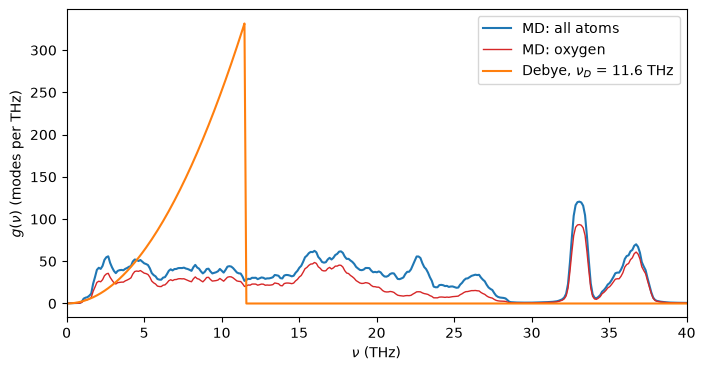

In [9]:
live = fixed.start(state, ensemble="nve")
live.advance(1000)
velocities = []
for _ in range(4096):
    live.advance(2)
    velocities.append(live.velocities)
velocities = np.array(velocities)                    # (time, atoms, 3), Å/ps
dt = 2*0.001                                         # ps between samples

masses = state.masses
nu = np.fft.rfftfreq(len(velocities), dt)            # THz, since time is in ps
power = masses[None, :, None]*np.abs(np.fft.rfft(velocities, axis=0))**2
total = power.sum(axis=(1, 2))
scale = 3*len(masses)/np.trapezoid(total, nu)
g = scale*total
oxygen = state.atoms.species == "O"
g_O = scale*power[:, oxygen].sum(axis=(1, 2))

nu_D = k_B*theta["BKS"]/h/1e12                       # THz
debye = np.where(nu < nu_D, 9*len(masses)*nu**2/nu_D**3, 0)
smooth = np.convolve(g, np.ones(9)/9, mode="same")
plt.figure(figsize=(8, 4))
plt.plot(nu, smooth, color="C0", label="MD: all atoms")
plt.plot(nu, np.convolve(g_O, np.ones(9)/9, mode="same"), color="C3", lw=1, label="MD: oxygen")
plt.plot(nu, debye, color="C1", label=rf"Debye, $\nu_D$ = {nu_D:.1f} THz")
plt.xlim(0, 40)
plt.xlabel(r"$\nu$ (THz)")
plt.ylabel(r"$g(\nu)$ (modes per THz)")
plt.legend()
plt.show()

Below a few THz the spectrum follows Debye's ν² law: these are the long sound waves
the elastic constants describe, and the sound speeds put all 3N modes below ν_D =
11.6 THz. The real spectrum spreads them out to 38 THz. Quartz has nine atoms in its
unit cell, so besides the three acoustic branches it has 24 optical ones, in which
the atoms of a cell move against each other. The narrow bands at 33 and 37 THz
(1100–1250 cm⁻¹, near where quartz absorbs infrared light) are Si–O stretching,
in which mostly the light oxygen atoms move. A narrow band is a group of nearly
equal frequencies, like a set of Einstein oscillators.

## Heat capacity

MD is classical, so every vibration holds k_B T and the heat capacity is 3Nk_B at any
temperature. Quantum mechanics freezes out a vibration of frequency ν when
k_B T ≪ hν; with the spectrum,

$$\frac{C_V}{3Nk_B} = \frac{1}{3N}\int g(\nu)\,\frac{x^2 e^x}{(e^x - 1)^2}\,d\nu,
\qquad x = \frac{h\nu}{k_BT}.$$

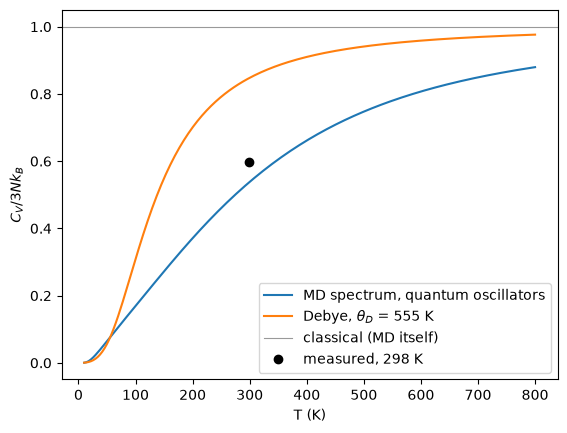

At 300 K: spectrum 0.54, Debye 0.85, measured 0.60 (C_p = 44.6 J/(mol K) per mole of SiO2)


In [10]:
T = np.linspace(10, 800, 200)                       # K; quartz turns into beta-quartz at 846 K
x = h*nu[1:, None]*1e12/(k_B*T[None, :])
C_spectrum = np.trapezoid(g[1:, None]*x**2*np.exp(-x)/(1 - np.exp(-x))**2, nu[1:], axis=0)/(3*len(masses))
y = np.linspace(1e-6, 1, 400)[:, None]*(theta["BKS"]/T)[None, :]
C_debye = 3*(T/theta["BKS"])**3*np.trapezoid(y**4*np.exp(-y)/(1 - np.exp(-y))**2, y, axis=0)

R = 8.314462618                                       # J/(mol K)
plt.plot(T, C_spectrum, label="MD spectrum, quantum oscillators")
plt.plot(T, C_debye, label=rf"Debye, $\theta_D$ = {theta['BKS']:.0f} K")
plt.axhline(1, color="0.6", lw=0.8, label="classical (MD itself)")
plt.plot(298.15, 44.6/(9*R), "ko", label="measured, 298 K")
plt.xlabel("T (K)")
plt.ylabel(r"$C_V / 3Nk_B$")
plt.legend()
plt.show()
print(f"At 300 K: spectrum {np.interp(300, T, C_spectrum):.2f}, Debye {np.interp(300, T, C_debye):.2f}, "
      f"measured {44.6/(9*R):.2f} (C_p = 44.6 J/(mol K) per mole of SiO2)")

At room temperature quartz has only 60% of its classical heat capacity (the
measured C_p; C_V is less than 1% smaller for quartz). The Debye model, built from
the speed of sound, predicts 85%: it puts every vibration below ν_D, while most of
quartz's vibrations lie well above k_BT/h ≈ 6 THz at 300 K and are still largely
frozen. The simulated spectrum, with each vibration treated as a quantum
oscillator, gives 54%. So Debye's picture is right for the sound waves and
Einstein's for the optical bands, and quartz needs both. The remaining difference,
54% against 60%, says that BKS's vibrations are on average a little higher in
frequency than real quartz's.

Each curve is a model built on the classical simulation: MD itself, with classical
atoms, has the heat capacity 3Nk_B at every temperature.